### 1. Global Earthquakes

In this problem set, we will use this file from the USGS Earthquakes Database. The dataset is similar to the one you use in Assignment 02. Use the file provided (usgs_earthquakes.csv) to recreate the following map. Use the mag column for magnitude. 

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

In [2]:
# 读取数据并筛选出震级最大的前 50 个地震
df = pd.read_csv(r"D:\SUST\ESE\Assignment\Assignment4\usgs_earthquakes.csv")
top_50 = df.sort_values(by='mag', ascending=False).head(50)

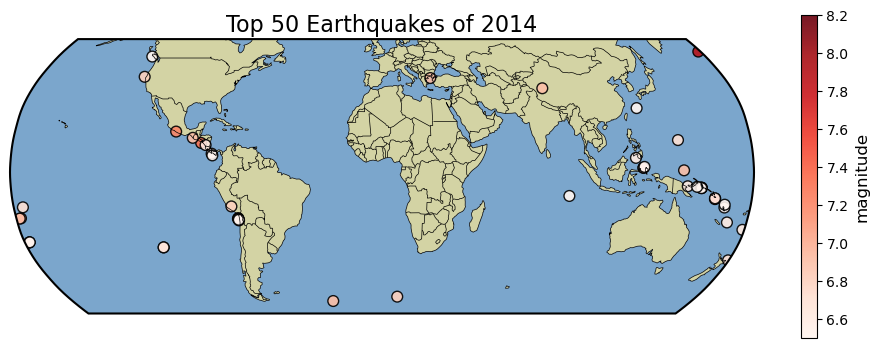

In [3]:
# 画图
fig = plt.figure(figsize=(12, 7))
ax = plt.axes(projection=ccrs.Robinson())

ax.add_feature(cfeature.LAND, facecolor='#d3d3a4')
ax.add_feature(cfeature.OCEAN, facecolor='#7ba6cc')
ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
ax.add_feature(cfeature.BORDERS, linewidth=0.5)
ax.spines['geo'].set_linewidth(1.5)

sc = ax.scatter(top_50['longitude'], top_50['latitude'], 
                c=top_50['mag'], 
                s=60,
                cmap='Reds', 
                edgecolors='black', 
                linewidths=1, 
                alpha=0.9,
                transform=ccrs.PlateCarree())

plt.title('Top 50 Earthquakes of 2014', fontsize=16)

cbar = plt.colorbar(sc, ax=ax, shrink=0.6, pad=0.05)
cbar.set_label('magnitude', fontsize=12)

plt.show()

### 2. Explore a netCDF dataset

Browse the NASA’s Goddard Earth Sciences Data and Information Services Center (GES DISC) website. Search and download a dataset you are interested in. You are also welcome to use data from your group in this problem set. But the dataset should be in netCDF format. For this problem set, you are welcome to use the same dataset you used in Assignment 03.

2.1 Make a global map of a certain variable. Your figure should contain: a project, x label and ticks, y label and ticks, title, gridlines, legend, colorbar, masks or features, annotations, and text box (1 point each).

选用了自己的 NCEP/NCAR Reanalysis 月度平均气温数据（0.995 sigma 层），来自 NOAA ESRL PSD。

In [4]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
from matplotlib.patches import Patch

In [5]:
# 读取数据
ds = xr.open_dataset(r"D:\SUST\ESE\Assignment\Assignment3\air.sig995.mon.mean.nc")
air_mean = ds['air'].mean(dim='time')
lat = ds['lat'].values
lon = ds['lon'].values

In [6]:
# 处理经度
lon_plot = np.where(lon > 180, lon - 360, lon)
sort_idx = np.argsort(lon_plot)
lon_plot = lon_plot[sort_idx]
air_plot = air_mean.values[:, sort_idx]

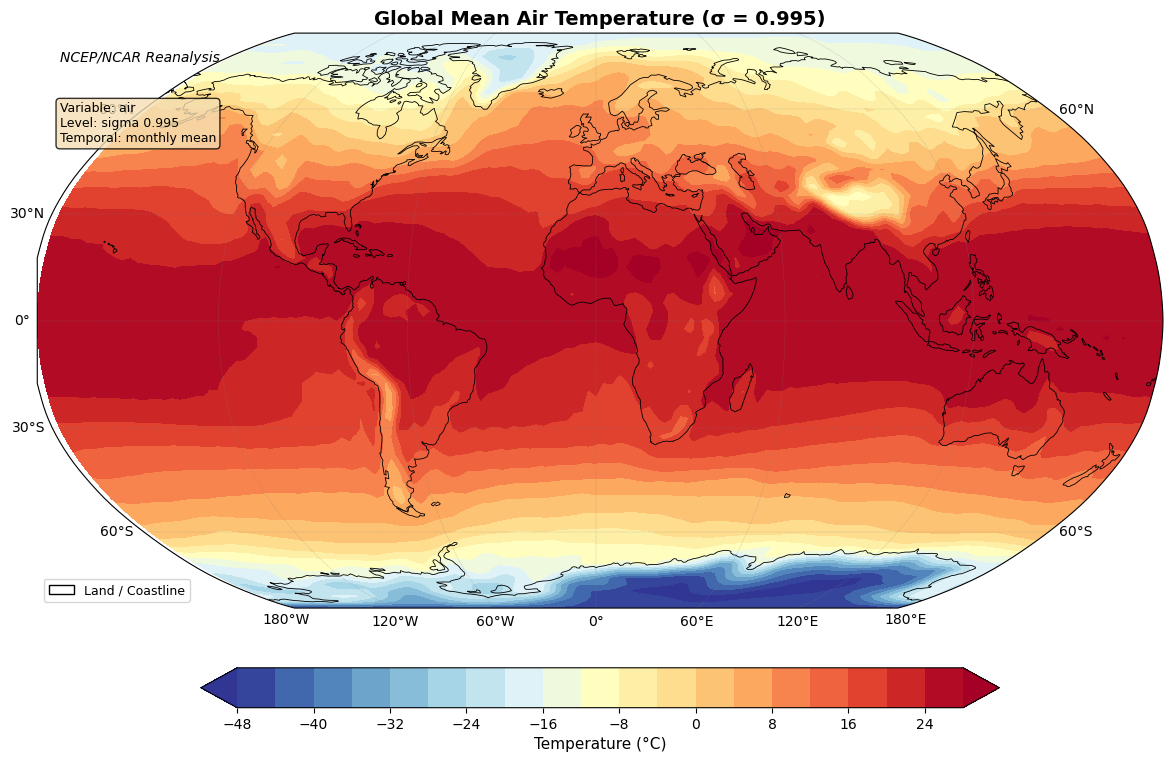

In [7]:
# 全球地图（Robinson 投影）
fig1 = plt.figure(figsize=(12, 8))
ax1 = plt.axes(projection=ccrs.Robinson())

cf1 = ax1.contourf(lon_plot, lat, air_plot, levels=20,
                   transform=ccrs.PlateCarree(), cmap='RdYlBu_r', extend='both')

ax1.coastlines(linewidth=0.6)
ax1.add_feature(cfeature.LAND, facecolor='none', edgecolor='gray', linewidth=0.3)

gl1 = ax1.gridlines(draw_labels=True, linewidth=0.3, color='gray', alpha=0.5, linestyle='--')
gl1.top_labels = False
gl1.right_labels = False
gl1.xformatter = LONGITUDE_FORMATTER
gl1.yformatter = LATITUDE_FORMATTER

ax1.set_xlabel('Longitude', fontsize=12)
ax1.set_ylabel('Latitude', fontsize=12)
ax1.set_title('Global Mean Air Temperature (σ = 0.995)', fontsize=14, fontweight='bold')

cbar1 = plt.colorbar(cf1, ax=ax1, orientation='horizontal', pad=0.08, shrink=0.7)
cbar1.set_label('Temperature (°C)', fontsize=11)

#图例
legend_elements = [Patch(facecolor='none', edgecolor='black', label='Land / Coastline')]
ax1.legend(handles=legend_elements, loc='lower left', fontsize=9)

ax1.annotate('NCEP/NCAR Reanalysis', xy=(0.02, 0.95), xycoords='axes fraction', fontsize=10, fontstyle='italic')
ax1.text(0.02, 0.88, 'Variable: air\nLevel: sigma 0.995\nTemporal: monthly mean',
         transform=ax1.transAxes, fontsize=9, verticalalignment='top',
         bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))

plt.tight_layout()
plt.savefig('global_map_fixed.png', dpi=150)
plt.show()

2.2 Make a regional map of the same variable. Your figure should contain: a different project, x label and ticks, y label and ticks, title, gridlines, legend, colorbar, masks or features, annotations, and text box (1 point each).

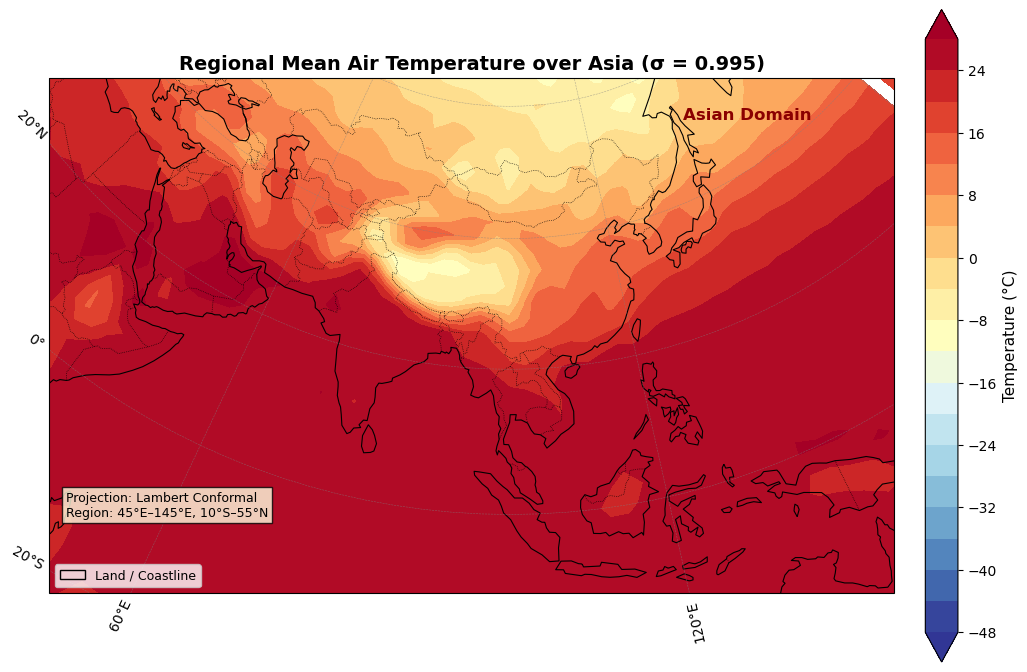

In [8]:
# 区域地图（亚洲，Lambert Conformal 投影）
fig2 = plt.figure(figsize=(11, 9))
ax2 = plt.axes(projection=ccrs.LambertConformal(central_longitude=100, central_latitude=35))

ax2.set_extent([45, 145, -10, 55], crs=ccrs.PlateCarree())

cf2 = ax2.contourf(lon_plot, lat, air_plot, levels=20,
                   transform=ccrs.PlateCarree(), cmap='RdYlBu_r', extend='both')

ax2.coastlines(linewidth=0.8)
ax2.add_feature(cfeature.BORDERS, linestyle=':', linewidth=0.5)
ax2.add_feature(cfeature.LAND, facecolor='none', edgecolor='gray', linewidth=0.3)

gl2 = ax2.gridlines(draw_labels=True, linewidth=0.4, color='gray', alpha=0.6, linestyle='--')
gl2.top_labels = False
gl2.right_labels = False
gl2.x_inline = False 
gl2.y_inline = False 
gl2.xformatter = LONGITUDE_FORMATTER
gl2.yformatter = LATITUDE_FORMATTER

ax2.set_xlabel('Longitude', fontsize=12)
ax2.set_ylabel('Latitude', fontsize=12)
ax2.set_title('Regional Mean Air Temperature over Asia (σ = 0.995)', fontsize=14, fontweight='bold')

cbar2 = plt.colorbar(cf2, ax=ax2, orientation='vertical', pad=0.03, shrink=0.75)
cbar2.set_label('Temperature (°C)', fontsize=11)

legend_elements2 = [Patch(facecolor='none', edgecolor='black', label='Land / Coastline')]
ax2.legend(handles=legend_elements2, loc='lower left', fontsize=9)

ax2.annotate('Asian Domain', xy=(0.75, 0.92), xycoords='axes fraction',
             fontsize=12, color='darkred', fontweight='bold')
ax2.text(0.02, 0.15, 'Projection: Lambert Conformal\nRegion: 45°E–145°E, 10°S–55°N',
         transform=ax2.transAxes, fontsize=9,
         bbox=dict(boxstyle='square', facecolor='lightyellow', alpha=0.8))

plt.tight_layout()
plt.savefig('regional_map_fixed.png', dpi=150)
plt.show()